In [1]:
# ==============================================================
# LOCAL PROJECT SETUP (added during VS Code migration)
# Portable replacement for Google Colab / Google Drive mounting.
# All research code below this block is unchanged.
# ==============================================================
import sys as _sys
from pathlib import Path as _Path

def _locate_project_root():
    start = _Path.cwd().resolve()
    for candidate in [start] + list(start.parents):
        if (candidate / "src" / "ecg_qpain" / "paths.py").is_file():
            return candidate
    return start

PROJECT_ROOT = _locate_project_root()
_src = str(PROJECT_ROOT / "src")
if _src not in _sys.path:
    _sys.path.insert(0, _src)

from ecg_qpain.paths import (
    ROOT, BASE_DIR, PROJECT_DIR, DRIVE_DIR, MYDRIVE, MOUNT_POINT, mount_path,
    DATA_DIR, RAW_DIR, PROCESSED_DIR, MODELS_DIR, REPORTS_DIR,
    MITDB_DIR, NSTDB_DIR, MITDB_EXTRACTED, NSTDB_EXTRACTED,
    B2_DIR, B3_DIR, B4_DIR,
)
print("Local project root:", PROJECT_ROOT)
# ==============================================================

# (pip install moved to requirements.txt; run: pip install -r requirements.txt)

import os
import wfdb
import numpy as np
import pandas as pd

from scipy.signal import butter, filtfilt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# (Colab Drive import removed - local execution)

# (Colab Drive mount removed - local execution)

Mounted at /content/gdrive


In [3]:
BASE_DIR = str(PROJECT_ROOT)

MITDB_DIR = os.path.join(
    BASE_DIR,
    "data/raw/mitdb/mit-bih-arrhythmia-database-1.0.0"
)

REPORT_DIR = os.path.join(BASE_DIR, "reports")

PROCESSED_DIR = os.path.join(
    BASE_DIR,
    "data/processed"
)

os.makedirs(PROCESSED_DIR, exist_ok=True)

# Load patient-independent split
record_split_df = pd.read_csv(
    os.path.join(REPORT_DIR, "record_split_assignment.csv")
)

print("MIT-BIH directory:", os.path.exists(MITDB_DIR))
print("Records in split file:", len(record_split_df))
print("Processed directory:", PROCESSED_DIR)

MIT-BIH directory: True
Records in split file: 48
Processed directory: /content/gdrive/MyDrive/ECG_QPAIN_2027/data/processed


In [4]:
FS = 360

BEFORE_R = 126
AFTER_R = 162

BEAT_LENGTH = BEFORE_R + AFTER_R

CLASS_MAPPING = {
    "N": ["N", "L", "R", "e", "j"],
    "S": ["A", "a", "J", "S"],
    "V": ["V", "E"],
    "F": ["F"]
}

SYMBOL_TO_CLASS = {
    symbol: class_name
    for class_name, symbols in CLASS_MAPPING.items()
    for symbol in symbols
}

print("Sampling Frequency:", FS)
print("Beat Length:", BEAT_LENGTH)
print("Before R-peak:", BEFORE_R)
print("After R-peak:", AFTER_R)

Sampling Frequency: 360
Beat Length: 288
Before R-peak: 126
After R-peak: 162


In [5]:
record_name = "100"

record_path = os.path.join(
    MITDB_DIR,
    record_name
)

signal, fields = wfdb.rdsamp(record_path)

print("Record:", record_name)
print("Signal Shape:", signal.shape)
print("Sampling Frequency:", fields["fs"])
print("Channel Names:", fields["sig_name"])
print("Signal Units:", fields["units"])

Record: 100
Signal Shape: (650000, 2)
Sampling Frequency: 360
Channel Names: ['MLII', 'V5']
Signal Units: ['mV', 'mV']


In [6]:
records = sorted(
    record_split_df["Record"].astype(str).tolist()
)

channel_audit = []

for record in records:

    record_path = os.path.join(
        MITDB_DIR,
        record
    )

    header = wfdb.rdheader(record_path)

    channel_audit.append({
        "Record": record,
        "Sampling_Frequency": header.fs,
        "Channels": ", ".join(header.sig_name),
        "Number_of_Channels": header.n_sig
    })

channel_df = pd.DataFrame(channel_audit)

display(channel_df)

channel_df.to_csv(
    os.path.join(REPORT_DIR, "ecg_channel_audit.csv"),
    index=False
)

print("Channel audit saved!")

,Record,Sampling_Frequency,Channels,Number_of_Channels
0,100,360,"MLII, V5",2
1,101,360,"MLII, V1",2
2,102,360,"V5, V2",2
3,103,360,"MLII, V2",2
4,104,360,"V5, V2",2
5,105,360,"MLII, V1",2
6,106,360,"MLII, V1",2
7,107,360,"MLII, V1",2
8,108,360,"MLII, V1",2
9,109,360,"MLII, V1",2


Channel audit saved!


In [7]:
def select_ecg_channel(channels):
    channel_list = [ch.strip() for ch in channels.split(",")]

    if "MLII" in channel_list:
        return "MLII"
    elif "V5" in channel_list:
        return "V5"
    else:
        return None


channel_audit_df["Selected_Channel"] = (
    channel_audit_df["Channels"].apply(select_ecg_channel)
)

print(channel_audit_df[
    ["Record", "Channels", "Selected_Channel"]
].to_string(index=False))

print("\nSelected Channel Counts:")
print(channel_audit_df["Selected_Channel"].value_counts())

print("\nRecords without selected channel:")
print(
    channel_audit_df[
        channel_audit_df["Selected_Channel"].isna()
    ]
)

NameError: name 'channel_audit_df' is not defined

In [8]:
import os
import pandas as pd

BASE_DIR = str(PROJECT_ROOT)
REPORT_DIR = os.path.join(BASE_DIR, "reports")

channel_audit_path = os.path.join(
    REPORT_DIR,
    "ecg_channel_audit.csv"
)

channel_audit_df = pd.read_csv(channel_audit_path)

print("Channel audit loaded successfully!")
print(channel_audit_df.head())
print("Total records:", len(channel_audit_df))

Channel audit loaded successfully!
   Record  Sampling_Frequency  Channels  Number_of_Channels
0     100                 360  MLII, V5                   2
1     101                 360  MLII, V1                   2
2     102                 360    V5, V2                   2
3     103                 360  MLII, V2                   2
4     104                 360    V5, V2                   2
Total records: 48


In [10]:
def select_ecg_channel(channels):

    channel_list = [ch.strip() for ch in channels.split(",")]

    if "MLII" in channel_list:
        return "MLII"
    elif "V5" in channel_list:
        return "V5"
    else:
        return None


channel_audit_df["Selected_Channel"] = (
    channel_audit_df["Channels"].apply(select_ecg_channel)
)

print("Selected Channel Counts:")
print(channel_audit_df["Selected_Channel"].value_counts())

print("\nRecords without selected channel:")
print(channel_audit_df[
    channel_audit_df["Selected_Channel"].isna()
])

Selected Channel Counts:
Selected_Channel
MLII    46
V5       2
Name: count, dtype: int64

Records without selected channel:
Empty DataFrame
Columns: [Record, Sampling_Frequency, Channels, Number_of_Channels, Selected_Channel]
Index: []


In [11]:
channel_audit_df.to_csv(
    channel_audit_path,
    index=False
)

print("Updated channel audit saved!")

Updated channel audit saved!


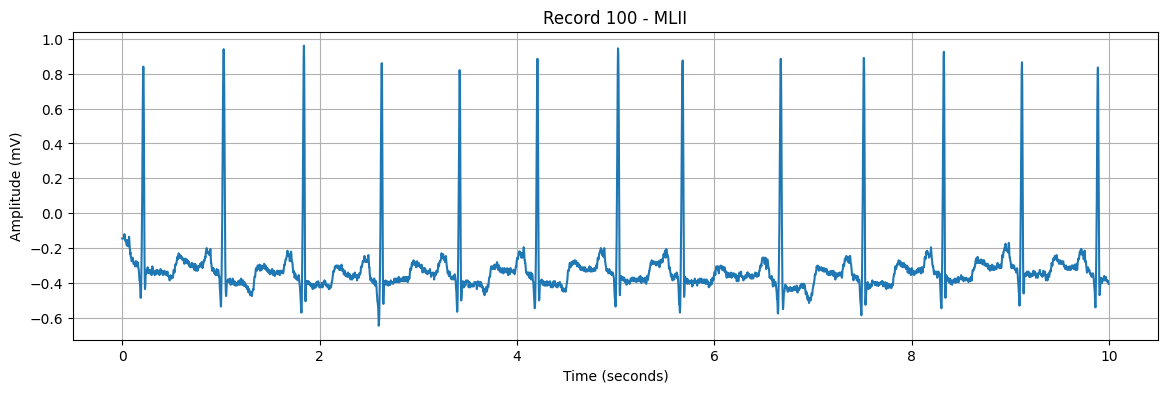

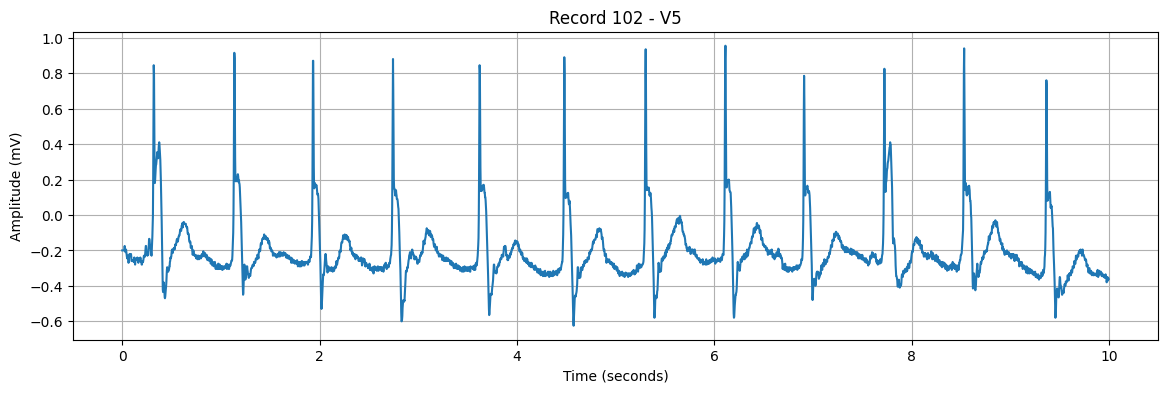

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import wfdb
import os

MITDB_DIR = os.path.join(
    BASE_DIR,
    "data/raw/mitdb/mit-bih-arrhythmia-database-1.0.0"
)

FS = 360

def plot_selected_ecg(record_id):

    record_path = os.path.join(MITDB_DIR, str(record_id))

    signal, fields = wfdb.rdsamp(record_path)

    row = channel_audit_df[
        channel_audit_df["Record"].astype(str) == str(record_id)
    ].iloc[0]

    selected_channel = row["Selected_Channel"]
    channel_index = fields["sig_name"].index(selected_channel)

    ecg_signal = signal[:, channel_index]

    samples = 10 * FS

    plt.figure(figsize=(14, 4))

    plt.plot(
        np.arange(samples) / FS,
        ecg_signal[:samples]
    )

    plt.title(f"Record {record_id} - {selected_channel}")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude (mV)")
    plt.grid(True)
    plt.show()


plot_selected_ecg("100")
plot_selected_ecg("102")

In [13]:
from scipy.signal import butter, sosfiltfilt

LOWCUT = 0.5
HIGHCUT = 40.0
FILTER_ORDER = 4

def bandpass_filter(signal, fs=360):

    nyquist = fs / 2

    sos = butter(
        FILTER_ORDER,
        [LOWCUT, HIGHCUT],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    filtered_signal = sosfiltfilt(sos, signal)

    return filtered_signal.astype(np.float32)


print("Bandpass filter function created!")

Bandpass filter function created!


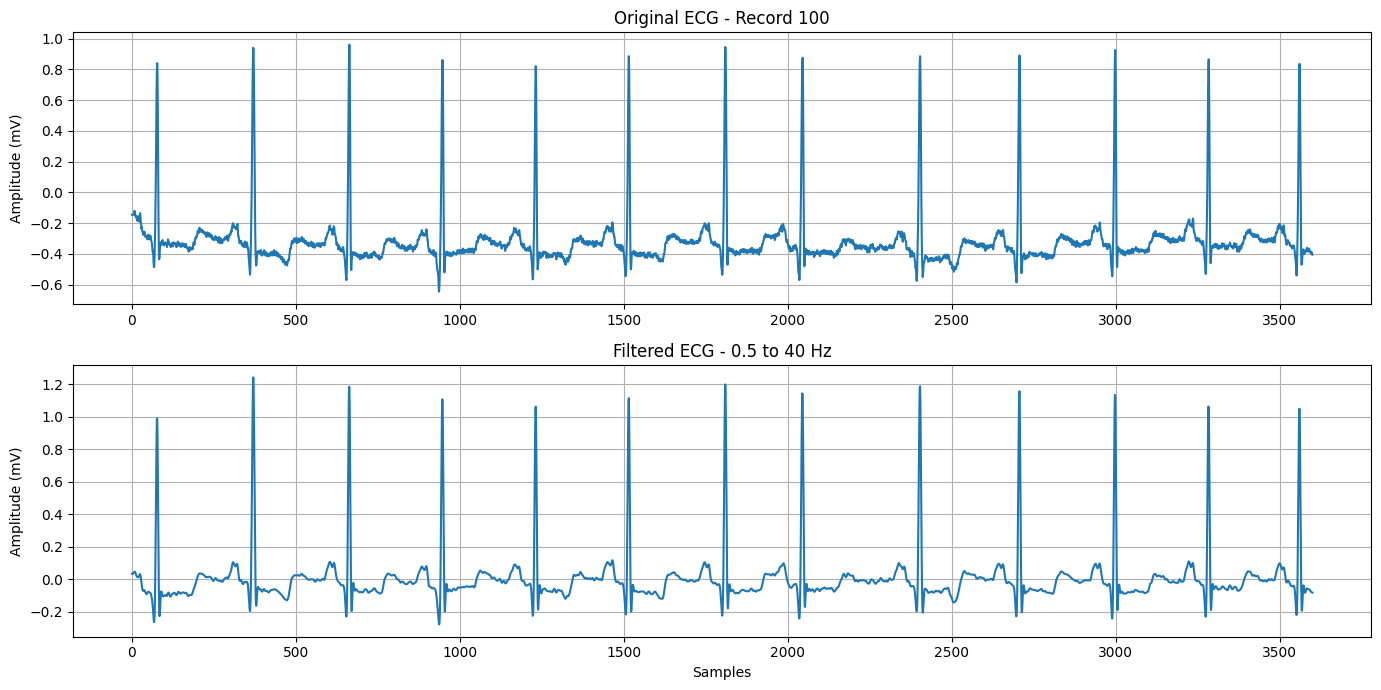

In [14]:
record_path = os.path.join(MITDB_DIR, "100")

signal, fields = wfdb.rdsamp(record_path)

channel_index = fields["sig_name"].index("MLII")

original_signal = signal[:, channel_index]

filtered_signal = bandpass_filter(
    original_signal,
    FS
)

samples = 10 * FS

plt.figure(figsize=(14, 7))

plt.subplot(2, 1, 1)
plt.plot(original_signal[:samples])
plt.title("Original ECG - Record 100")
plt.ylabel("Amplitude (mV)")
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(filtered_signal[:samples])
plt.title("Filtered ECG - 0.5 to 40 Hz")
plt.xlabel("Samples")
plt.ylabel("Amplitude (mV)")
plt.grid()

plt.tight_layout()
plt.show()

In [15]:
record_split_df = pd.read_csv(
    os.path.join(REPORT_DIR, "record_split_assignment.csv")
)

print("Columns:")
print(record_split_df.columns.tolist())

print("\nFirst five rows:")
display(record_split_df.head())

Columns:
['Record', 'Patient_Group', 'N', 'S', 'V', 'F', 'Split']

First five rows:


,Record,Patient_Group,N,S,V,F,Split
0,100,patient_100,2239,33,1,0,Validation
1,101,patient_101,1860,3,0,0,Train
2,102,patient_102,99,0,4,0,Train
3,103,patient_103,2082,2,0,0,Train
4,104,patient_104,163,0,2,0,Validation


In [16]:
AAMI_MAP = {
    "N": ["N", "L", "R", "e", "j"],
    "S": ["A", "a", "J", "S"],
    "V": ["V", "E"],
    "F": ["F"]
}

SYMBOL_TO_CLASS = {
    symbol: class_name
    for class_name, symbols in AAMI_MAP.items()
    for symbol in symbols
}

CLASS_TO_LABEL = {
    "N": 0,
    "S": 1,
    "V": 2,
    "F": 3
}

print("AAMI mapping created!")
print(SYMBOL_TO_CLASS)

AAMI mapping created!
{'N': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N', 'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S', 'V': 'V', 'E': 'V', 'F': 'F'}


In [17]:
FS = 360

BEFORE_R = 126
AFTER_R = 162

BEAT_LENGTH = BEFORE_R + AFTER_R

print("Sampling Frequency:", FS)
print("Before R-peak:", BEFORE_R)
print("After R-peak:", AFTER_R)
print("Beat Length:", BEAT_LENGTH)

Sampling Frequency: 360
Before R-peak: 126
After R-peak: 162
Beat Length: 288


In [18]:
import numpy as np
import pandas as pd
import os
import wfdb
from tqdm.notebook import tqdm

# Load split information
record_split_df = pd.read_csv(
    os.path.join(REPORT_DIR, "record_split_assignment.csv")
)

record_split_df["Record"] = (
    record_split_df["Record"].astype(str)
)

split_map = dict(
    zip(
        record_split_df["Record"],
        record_split_df["Split"]
    )
)

patient_map = dict(
    zip(
        record_split_df["Record"],
        record_split_df["Patient_Group"]
    )
)

channel_map = dict(
    zip(
        channel_audit_df["Record"].astype(str),
        channel_audit_df["Selected_Channel"]
    )
)

# Storage
X_data = {
    "Train": [],
    "Validation": [],
    "Test": []
}

y_data = {
    "Train": [],
    "Validation": [],
    "Test": []
}

metadata = {
    "Train": [],
    "Validation": [],
    "Test": []
}

excluded_count = 0
boundary_count = 0

records = sorted(split_map.keys())

for record_id in tqdm(records):

    record_path = os.path.join(MITDB_DIR, record_id)

    # Read ECG
    signal, fields = wfdb.rdsamp(record_path)

    selected_channel = channel_map[record_id]

    channel_index = fields["sig_name"].index(
        selected_channel
    )

    ecg_signal = signal[:, channel_index]

    # Filter ECG
    filtered_signal = bandpass_filter(
        ecg_signal,
        FS
    )

    # Read annotations
    annotation = wfdb.rdann(
        record_path,
        "atr"
    )

    split_name = split_map[record_id]
    patient_group = patient_map[record_id]

    # Process annotations in original order
    for sample, symbol in zip(
        annotation.sample,
        annotation.symbol
    ):

        if symbol not in SYMBOL_TO_CLASS:
            excluded_count += 1
            continue

        start = sample - BEFORE_R
        end = sample + AFTER_R

        # Boundary check
        if start < 0 or end > len(filtered_signal):
            boundary_count += 1
            continue

        beat = filtered_signal[start:end]

        if len(beat) != BEAT_LENGTH:
            continue

        class_name = SYMBOL_TO_CLASS[symbol]
        label = CLASS_TO_LABEL[class_name]

        X_data[split_name].append(beat)
        y_data[split_name].append(label)

        metadata[split_name].append({
            "Record": record_id,
            "Patient_Group": patient_group,
            "Sample": int(sample),
            "Annotation": symbol,
            "Class": class_name,
            "Label": label,
            "Split": split_name,
            "Selected_Channel": selected_channel
        })

print("\nBeat extraction completed!")
print("Excluded annotations:", excluded_count)
print("Boundary beats:", boundary_count)

  0%|          | 0/48 [00:00<?, ?it/s]


Beat extraction completed!
Excluded annotations: 11196
Boundary beats: 45


In [19]:
for split_name in ["Train", "Validation", "Test"]:

    X_data[split_name] = np.asarray(
        X_data[split_name],
        dtype=np.float32
    )

    y_data[split_name] = np.asarray(
        y_data[split_name],
        dtype=np.int64
    )

    metadata[split_name] = pd.DataFrame(
        metadata[split_name]
    )

    print("\n", split_name)

    print("X shape:", X_data[split_name].shape)
    print("y shape:", y_data[split_name].shape)


 Train
X shape: (59720, 288)
y shape: (59720,)

 Validation
X shape: (19530, 288)
y shape: (19530,)

 Test
X shape: (22156, 288)
y shape: (22156,)


In [20]:
for split_name in ["Train", "Validation", "Test"]:

    print("\n", split_name, "Class Distribution")

    print(
        metadata[split_name]["Class"].value_counts()
        .reindex(["N", "S", "V", "F"], fill_value=0)
    )


 Train Class Distribution
Class
N    53119
S     1956
V     4225
F      420
Name: count, dtype: int64

 Validation Class Distribution
Class
N    17533
S      462
V     1518
F       17
Name: count, dtype: int64

 Test Class Distribution
Class
N    19936
S      363
V     1492
F      365
Name: count, dtype: int64


In [21]:
PROCESSED_DIR = os.path.join(
    BASE_DIR,
    "data",
    "processed"
)

os.makedirs(PROCESSED_DIR, exist_ok=True)

for split_name in ["Train", "Validation", "Test"]:

    np.savez_compressed(
        os.path.join(
            PROCESSED_DIR,
            f"{split_name.lower()}_beats.npz"
        ),
        X=X_data[split_name],
        y=y_data[split_name]
    )

    metadata[split_name].to_csv(
        os.path.join(
            PROCESSED_DIR,
            f"{split_name.lower()}_metadata.csv"
        ),
        index=False
    )

print("All datasets saved successfully!")
print("Location:", PROCESSED_DIR)

All datasets saved successfully!
Location: /content/gdrive/MyDrive/ECG_QPAIN_2027/data/processed


In [22]:
print("Excluded annotations:", excluded_count)
print("Boundary beats:", boundary_count)

print("\nExtracted total beats:")

for split_name in ["Train", "Validation", "Test"]:
    print(split_name, len(y_data[split_name]))

print(
    "\nTotal extracted:",
    sum(len(y_data[s]) for s in ["Train", "Validation", "Test"])
)

Excluded annotations: 11196
Boundary beats: 45

Extracted total beats:
Train 59720
Validation 19530
Test 22156

Total extracted: 101406


In [23]:
for split_name in ["Train", "Validation", "Test"]:

    X = X_data[split_name]
    y = y_data[split_name]

    print("\n", split_name)

    print("Shape:", X.shape)
    print("Correct beat length:", X.shape[1] == 288)
    print("NaN values:", np.isnan(X).sum())
    print("Infinite values:", np.isinf(X).sum())
    print("Unique labels:", np.unique(y))
    print("Minimum amplitude:", X.min())
    print("Maximum amplitude:", X.max())

    assert X.shape[1] == 288
    assert np.isfinite(X).all()
    assert set(np.unique(y)).issubset({0, 1, 2, 3})

print("\nAll basic quality checks passed!")


 Train
Shape: (59720, 288)
Correct beat length: True
NaN values: 0
Infinite values: 0
Unique labels: [0 1 2 3]
Minimum amplitude: -3.102609
Maximum amplitude: 3.5222082

 Validation
Shape: (19530, 288)
Correct beat length: True
NaN values: 0
Infinite values: 0
Unique labels: [0 1 2 3]
Minimum amplitude: -3.5707395
Maximum amplitude: 4.052188

 Test
Shape: (22156, 288)
Correct beat length: True
NaN values: 0
Infinite values: 0
Unique labels: [0 1 2 3]
Minimum amplitude: -3.1775692
Maximum amplitude: 3.3283174

All basic quality checks passed!


In [24]:
train_patients = set(
    metadata["Train"]["Patient_Group"]
)

val_patients = set(
    metadata["Validation"]["Patient_Group"]
)

test_patients = set(
    metadata["Test"]["Patient_Group"]
)

print("Train-Val overlap:", train_patients & val_patients)
print("Train-Test overlap:", train_patients & test_patients)
print("Val-Test overlap:", val_patients & test_patients)

assert len(train_patients & val_patients) == 0
assert len(train_patients & test_patients) == 0
assert len(val_patients & test_patients) == 0

print("\nPatient independence verification PASSED!")

Train-Val overlap: set()
Train-Test overlap: set()
Val-Test overlap: set()

Patient independence verification PASSED!


In [25]:
# Count F-class beats for each patient

for split_name in ["Train", "Validation", "Test"]:

    print("\n", split_name, "F-class distribution")

    f_distribution = (
        metadata[split_name]
        [metadata[split_name]["Class"] == "F"]
        .groupby("Patient_Group")
        .size()
        .sort_values(ascending=False)
    )

    print(f_distribution)

    print(
        "Total F beats:",
        f_distribution.sum()
    )

    print(
        "Patients with F beats:",
        len(f_distribution)
    )


 Train F-class distribution
Patient_Group
patient_208        372
patient_223         14
patient_205         11
patient_210         10
patient_114          4
patient_201_202      3
patient_109          2
patient_108          2
patient_214          1
patient_219          1
dtype: int64
Total F beats: 420
Patients with F beats: 10

 Validation F-class distribution
Patient_Group
patient_233    11
patient_124     5
patient_215     1
dtype: int64
Total F beats: 17
Patients with F beats: 3

 Test F-class distribution
Patient_Group
patient_213    362
patient_200      2
patient_203      1
dtype: int64
Total F beats: 365
Patients with F beats: 3


In [26]:
quality_report = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Total_Beats": [
        len(y_data["Train"]),
        len(y_data["Validation"]),
        len(y_data["Test"])
    ],
    "Beat_Length": [288, 288, 288],
    "NaN_Count": [
        np.isnan(X_data[s]).sum()
        for s in ["Train", "Validation", "Test"]
    ],
    "Infinite_Count": [
        np.isinf(X_data[s]).sum()
        for s in ["Train", "Validation", "Test"]
    ]
})

quality_report.to_csv(
    os.path.join(REPORT_DIR, "dataset_quality_report.csv"),
    index=False
)

print(quality_report)
print("\nQuality report saved!")

        Split  Total_Beats  Beat_Length  NaN_Count  Infinite_Count
0       Train        59720          288          0               0
1  Validation        19530          288          0               0
2        Test        22156          288          0               0

Quality report saved!
